# KRAS inhibitor (MRTX1133) mouse lung Xenium: treatment effect from s, outcome predictor from z

3 control and 4 treated sections, 920 k cells. The per-nodule treatment effect (TE) is the salient composition
shift D([z,s]) − D([z,0]) averaged over a nodule's tumour cells; its main axis (94 %) is conversion toward
Itgb6+ persister tumour epithelium, and nodules with more conversion respond less (independent MAPK MPAS responder
rate, never seen by Haruka).

To find the background that goes with a bad TE, the TE is made s-specific (real − mean of 3 shuffled-s nulls).
Background axis **z-PC2** (alveolar-parenchymal niche: Nqo1/Ptgs2/Ager/Sdc1; endothelium, AT1/AT2, monocytes and
alveolar macrophages vs airway-adjacent ciliated/SMC) predicts the bad TE on held-out sections (3/4; +0.53 vs
responders −0.39) and exists before treatment (control SD ratio 0.94). Interactions: squidpy neighbourhood
enrichment and LIANA+ (lipid exchange Lpl–Sdc1, Apob–Lrp1 at the bad end; complement C3 at the good end).

In [1]:
import sys, pathlib; sys.path.insert(0, str(next(p for p in [pathlib.Path.cwd(), pathlib.Path.cwd() / 'notebooks'] if (p / 'repro.py').exists())))
from repro import run, require, show, fetch, STAGES, H, WK, PY, PY_VIO, GPU
# Default: end to end (download from Hugging Face -> fit -> analyses -> figure; hours on one GPU).
# Redraw only from saved outputs: STAGES.update(download=False, fit=False, analysis=False)  (or env HARUKA_FIGURE_ONLY=1)
# Rebuild the inputs from the raw public releases instead of Hugging Face: STAGES.update(data=True)
print(H, STAGES)

/home/yancui/haruka_v2 {'download': True, 'data': False, 'fit': False, 'analysis': False, 'figure': True}


## 0 Preprocessed data (Hugging Face)

The ready-to-fit inputs are read directly from [C1vy/haruka_v2_data](https://huggingface.co/datasets/C1vy/haruka_v2_data) (cached in `hf_data/`) and linked to the paths the scripts read. The data stage below rebuilds the same files from the raw releases and is off by default.

In [2]:
fetch('07_kras/mouselung_kras_xenium_clean_noC3.h5ad', H / 'data/mouselung_kras_xenium_clean_noC3.h5ad')

[download] 07_kras/mouselung_kras_xenium_clean_noC3.h5ad: /home/yancui/haruka_v2/data/mouselung_kras_xenium_clean_noC3.h5ad already present, kept


/home/yancui/.conda/envs/haruka2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PosixPath('/home/yancui/haruka_v2/data/mouselung_kras_xenium_clean_noC3.h5ad')

## 1 Data: the KRAS Xenium h5ad is distributed as-is (X = normalize+log1p, raw counts in `layers["counts"]`), fetched in section 0

In [3]:
require(H / 'data/mouselung_kras_xenium_clean_noC3.h5ad')

inputs present


True

## 2 Fit (default model; batch = slice, 2000 HVG, saves the model + 3 shuffled-s nulls; ~2.8 h on one GPU)

In [4]:
run(f'mkdir -p results_kras_te_null && bash bench_kras_xenium/run_kras_te_null_fit.sh {GPU}', 'fit', log='results_kras_te_null/fit.log')
require(H / 'results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/salient_composition_shift.npy', H / 'results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/null_shuffled_s_composition_shift_2.npy')

[skip: fit stage off] mkdir -p results_kras_te_null && bash bench_kras_xenium/run_kras_te_null_fit.sh 0
inputs present


True

## 3 Independent biological responder (MAPK MPAS, lower quartile of control per tumour subtype)

In [5]:
run(f'{PY} bench_kras_xenium/define_biological_responder.py', 'analysis', log='bench_kras_xenium/bio_responder.log')

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python bench_kras_xenium/define_biological_responder.py


## 4 Nodule treatment effect (panels i–l)

In [6]:
M = H / 'results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0'; N = ' '.join(str(M / f'null_shuffled_s_composition_shift_{k}.npy') for k in range(3))
NT = H / 'bench_kras_xenium/nodule_te'
run(f'{PY} nodule_te.py {M} refit {N}', 'analysis', cwd=NT, log='run_refit.out')
run(f'{PY} nodule_te.py {M} refit_ownTumEpi {N}', 'analysis', cwd=NT, env={'OWN_TYPE': 'Tumor_epithelial'}, log='run_refit_own.out')

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python nodule_te.py /home/yancui/haruka_v2/results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0 refit /home/yancui/haruka_v2/results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/null_shuffled_s_composition_shift_0.npy /home/yancui/haruka_v2/results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/null_shuffled_s_composition_shift_1.npy /home/yancui/haruka_v2/results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_shared_full_niche_compgated_decoderbatch8_batchmode-decoder_only_seed0/null_shuffled_s_composition_shift_2.npy
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python nodule_te.py /home/yancui/haruka_v2/results_kras_te_null/mouselung_kras_xenium_clean_noC3/haruka_sh

## 5 Which background goes with a bad TE; naming z-PC2; held-out prediction; interactions (panels m–v)

In [7]:
run(f'{PY} bad_te_background.py', 'analysis', cwd=NT)
run(f'{PY} name_bad_te_z.py', 'analysis', cwd=NT)
run(f'timeout 5400 {PY} zpc2_interactions.py', 'analysis', cwd=NT)

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python bad_te_background.py
[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python name_bad_te_z.py
[skip: analysis stage off] timeout 5400 /home/yancui/.conda/envs/haruka2/bin/python zpc2_interactions.py


In [8]:
import pandas as pd
display(pd.read_csv(NT / 'name_bad_te_heldout.csv').round(2))
display(pd.read_csv(NT / 'zpc2_interactions/A_summary.csv').round(3))

,held_out,axis,matched_pc,cos,n,rho_bad_te,rho_resp,rho_mpas
0,JB_M0,zPC2,3,0.98,46,0.43,-0.52,0.52
1,JB_M0,zPC3,2,0.99,46,0.06,0.34,-0.28
2,JB_M1,zPC2,2,1.00,31,-0.11,0.13,-0.12
3,JB_M1,zPC3,3,0.89,31,0.12,-0.38,-0.03
4,JB_M2,zPC2,3,0.91,36,0.63,-0.32,0.35
5,JB_M2,zPC3,2,0.91,36,-0.41,0.17,-0.04
6,JB_M3,zPC2,2,0.99,19,0.75,-0.45,-0.03
7,JB_M3,zPC3,3,0.83,19,0.06,-0.50,-0.13


,group,high,low,diff_median,sections_same_sign,p
0,Ciliated,0.235,0.354,-0.094,2,0.000
1,Pericyte/SMC,0.106,0.181,-0.060,2,0.000
2,T/NK,0.033,0.031,0.000,2,0.021
3,Monocyte,0.004,0.002,0.002,3,0.064
4,Fibroblast,0.071,0.057,0.004,2,0.009
5,B,0.029,0.020,0.006,2,0.006
6,Macrophage alveolar,0.019,0.010,0.008,4,0.005
7,Macrophage interstitial/mo,0.025,0.018,0.009,2,0.073
8,Neutrophil,0.028,0.020,0.014,3,0.066
9,DC,0.048,0.052,0.015,3,0.614


## 6 Figure data and the figure

In [9]:
K = H / 'figures_paper/kras'
run(f'{PY} kras_fig_data.py', 'analysis', cwd=K)
run(f'{PY} make_kras_figure.py', 'figure', cwd=K)

[skip: analysis stage off] /home/yancui/.conda/envs/haruka2/bin/python kras_fig_data.py


panels 22 | fonts below minimum: []
full page (2373, 2531)
[figure] exit 0 in 20s: /home/yancui/.conda/envs/haruka2/bin/python make_kras_figure.py


## Figure

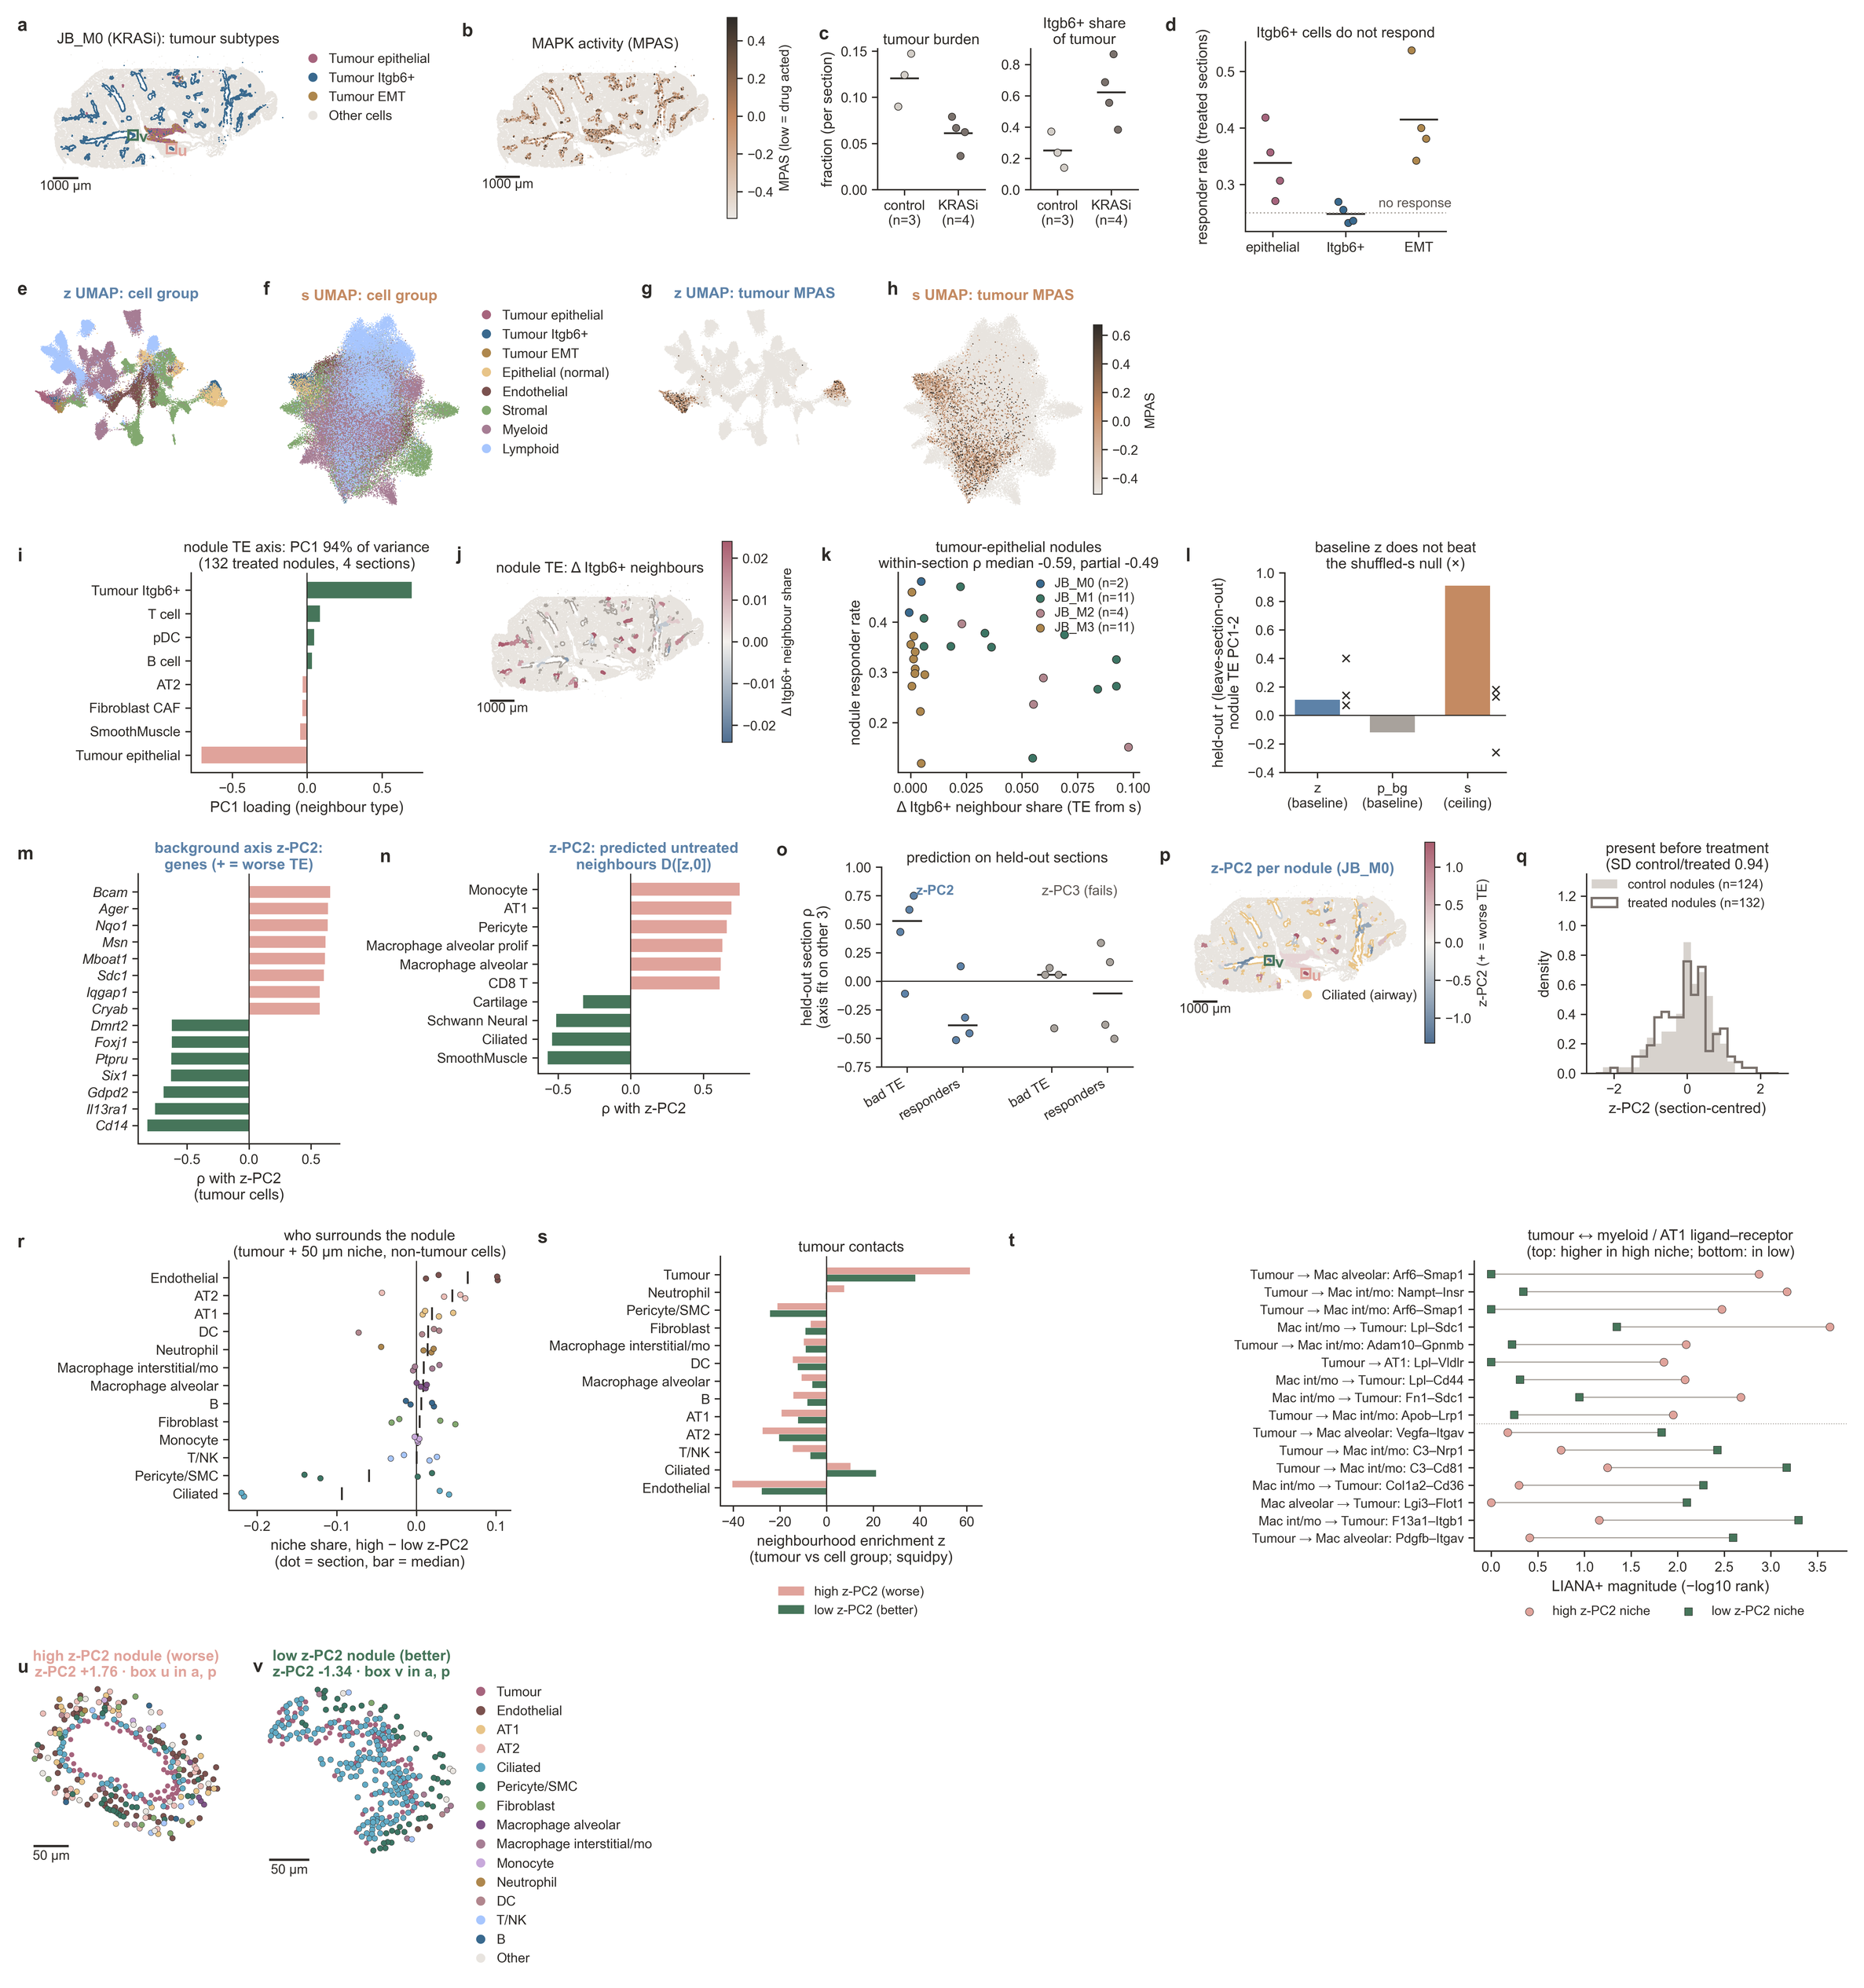

In [10]:
show(H / 'figures_paper/kras/KRAS_inhibitor_full.png')